# Working Pipline of RAGWire

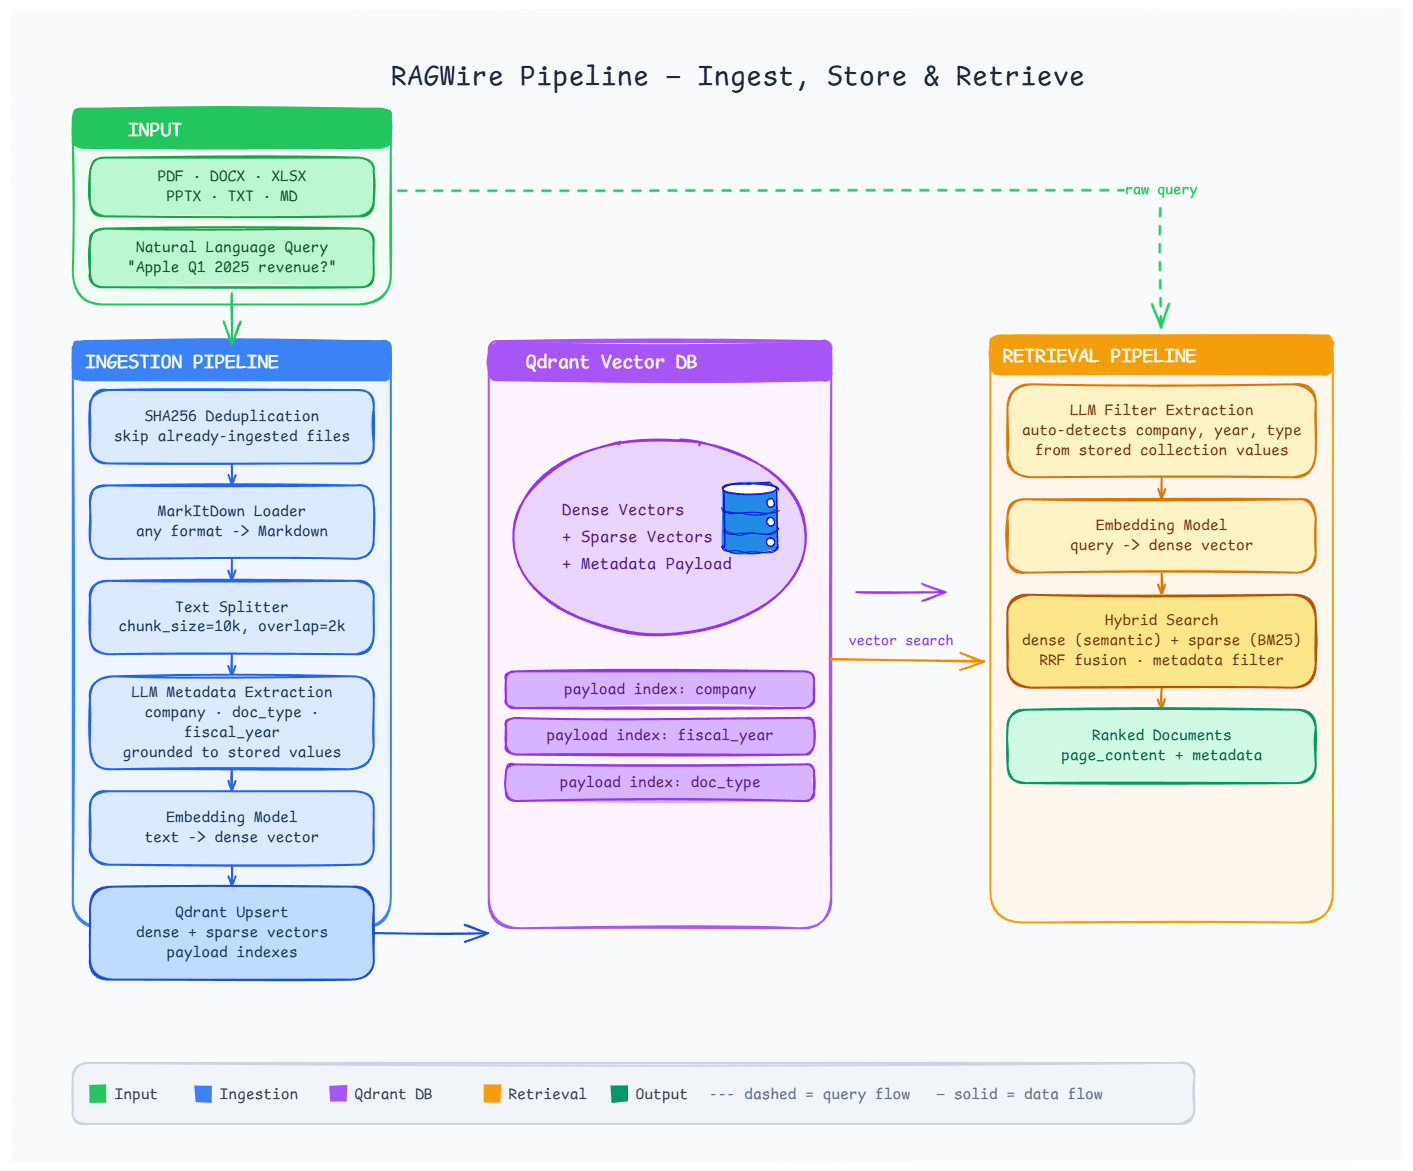

# Difference Between Embedding Only Search and Hybrid Search
![hybrid VS normal serach.png](<attachment:hybrid VS normal serach.png>)
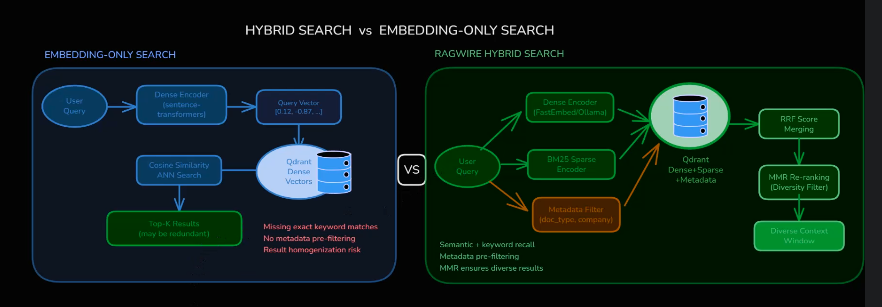

# Setup the RAGWire

In [1]:
from dotenv import load_dotenv
load_dotenv()


from ragwire import RAGWire, setup_logging
import ragwire

print(ragwire.__version__)

1.6.1


In [2]:
loger = setup_logging(log_level="INFO")

# Ingest a Single Document and Retrieve

In [3]:
rag = RAGWire('config.yaml')

2026-10-14 07:58:37,804 - ragwire.core.pipeline - INFO - Loading configuration from config.yaml
2026-10-14 07:58:39,013 - ragwire.core.pipeline - INFO - Document loader initialized
2026-10-14 07:58:39,014 - ragwire.core.pipeline - INFO - Text splitter initialized (strategy=markdown, chunk_size=10000)
2026-10-14 07:58:39,015 - ragwire.core.pipeline - INFO - Ingestion configured (workers=1, batch_size=64, retries=2, replace_changed=True)
2026-10-14 07:58:39,299 - ragwire.core.pipeline - INFO - Embedding model initialized (provider=ollama)
2026-10-14 07:58:39,316 - ragwire.core.pipeline - INFO - LLM initialized for metadata extraction (provider=ollama, model=qwen3:8b)
2026-10-14 07:58:40,155 - ragwire.vectorstores.qdrant_store - INFO - Connected to Qdrant at http://localhost:6333
2026-10-14 07:58:40,226 - ragwire.core.pipeline - INFO - Using existing collection: finance-rag-ollama
2026-10-14 07:58:40,925 - ragwire.core.pipeline - INFO - Vector store initialized
2026-10-14 07:58:40,925 - r

In [4]:
stats = rag.ingest_documents(["../00 Dataset/finance_data/Apple_10k_2025.pdf"])

2026-10-14 07:58:40,932 - ragwire.core.pipeline - INFO - Starting ingestion of 1 documents


Ingesting:   0%|          | 0/1 [00:00<?, ?file/s]

2026-10-14 07:58:40,993 - ragwire.core.pipeline - INFO - Skipping (already ingested): ../00 Dataset/finance_data/Apple_10k_2025.pdf


Ingesting: 100%|██████████| 1/1 [00:00<00:00, 18.40file/s]


2026-10-14 07:58:41,439 - ragwire.core.pipeline - INFO - Ingestion complete: 0/1 documents (1 skipped, 0 failed, 0 replaced, 0 chunks)


In [5]:
stats

{'total': 1,
 'processed': 0,
 'skipped': 1,
 'failed': 0,
 'chunks_created': 0,
 'metadata_failed': 0,
 'replaced': 0,
 'errors': []}

In [6]:
result = rag.retrieve("What is the apple's revenue?")

2026-10-14 07:58:41,567 - ragwire.core.pipeline - INFO - Retrieved 5 documents for query: What is the apple's revenue?...


In [7]:
result

[Document(metadata={'source': '..\\00 Dataset\\finance_data\\apple 10-k 2024.pdf', 'file_name': 'apple 10-k 2024.pdf', 'file_type': 'pdf', 'file_hash': 'ec74758cd767465362c641cf2fd5d8fedd477aed2bf7f62117e67610435dcb88', 'chunk_id': 'ec74758cd767465362c641cf2fd5d8fedd477aed2bf7f62117e67610435dcb88_21', 'chunk_hash': '175b515074343f9fb4fb9dd49342db773966eae5bffbc61db537d0ff2111b865', 'content_hash': '6d4887aa6bb7c856fd34c7cdd1d6de352dadc482069c22c3f6361e228ff0203a', 'chunk_index': 21, 'total_chunks': 57, 'created_at': '2026-10-14T00:53:02.749504+00:00', 'metadata_status': 'ok', 'company_name': 'apple inc.', 'doc_type': 'form 10-k', 'fiscal_quarter': None, 'fiscal_year': 2025, '_id': '0b3bd95b-142e-4a1e-b606-3dd59cfdd7a9', '_collection_name': 'finance-rag-ollama'}, page_content='Note 2 – Revenue\nThe Company recognizes revenue at the amount to which it expects to be entitled when control of the products or services is transferred to its customers.\nControl is generally transferred when th

# RAGWire and Agentic RAG

## Scale to Multiple Companies Ingesting the complete directory

In [8]:
rag.ingest_directory('../00 Dataset/finance_data')

2026-10-14 07:58:41,585 - ragwire.core.pipeline - INFO - Found 6 file(s) in ../00 Dataset/finance_data
2026-10-14 07:58:41,586 - ragwire.core.pipeline - INFO - Starting ingestion of 6 documents


Ingesting:   0%|          | 0/6 [00:00<?, ?file/s]

2026-10-14 07:58:41,682 - ragwire.core.pipeline - INFO - Skipping (already ingested): ..\00 Dataset\finance_data\amazon 10-k 2024.pdf
2026-10-14 07:58:41,750 - ragwire.core.pipeline - INFO - Skipping (already ingested): ..\00 Dataset\finance_data\amazon 10k 2025.pdf


Ingesting:  33%|███▎      | 2/6 [00:00<00:00, 12.25file/s]

2026-10-14 07:58:41,800 - ragwire.core.pipeline - INFO - Skipping (already ingested): ..\00 Dataset\finance_data\apple 10-k 2024.pdf
2026-10-14 07:58:41,836 - ragwire.core.pipeline - INFO - Skipping (already ingested): ..\00 Dataset\finance_data\Apple_10k_2025.pdf
2026-10-14 07:58:41,864 - ragwire.core.pipeline - INFO - Skipping (already ingested): ..\00 Dataset\finance_data\GOOG-10-K-2025.pdf


Ingesting:  83%|████████▎ | 5/6 [00:00<00:00, 19.30file/s]

2026-10-14 07:58:41,902 - ragwire.core.pipeline - INFO - Skipping (already ingested): ..\00 Dataset\finance_data\google 10-k 2024.pdf


Ingesting: 100%|██████████| 6/6 [00:00<00:00, 19.02file/s]


2026-10-14 07:58:42,248 - ragwire.core.pipeline - INFO - Ingestion complete: 0/6 documents (6 skipped, 0 failed, 0 replaced, 0 chunks)


{'total': 6,
 'processed': 0,
 'skipped': 6,
 'failed': 0,
 'chunks_created': 0,
 'metadata_failed': 0,
 'replaced': 0,
 'errors': []}

## Explore Metadata

In [9]:
rag.discover_metadata_fields()

['chunk_hash',
 'chunk_id',
 'chunk_index',
 'company_name',
 'content_hash',
 'created_at',
 'doc_type',
 'file_hash',
 'file_name',
 'file_type',
 'fiscal_quarter',
 'fiscal_year',
 'metadata_status',
 'source',
 'total_chunks']

In [10]:
rag.filter_fields

['company_name', 'doc_type', 'fiscal_quarter', 'fiscal_year']

## Manual Metadata Filters

In [11]:
query = "what is the amazon revenue in 2025"
result= rag.retrieve(query=query)

2026-10-14 07:58:42,370 - ragwire.core.pipeline - INFO - Retrieved 5 documents for query: what is the amazon revenue in 2025...


In [12]:
result

[Document(metadata={'source': '..\\00 Dataset\\finance_data\\amazon 10k 2025.pdf', 'file_name': 'amazon 10k 2025.pdf', 'file_type': 'pdf', 'file_hash': '2fc39243213f0c15e5e128c5600b37ce161a0a58f818070bc0e6af2ed1a44857', 'chunk_id': '2fc39243213f0c15e5e128c5600b37ce161a0a58f818070bc0e6af2ed1a44857_24', 'chunk_hash': '5691fd2c1b9d303b88e774b2408e904554f19b9a731702b1ef3f1eb031846ca0', 'content_hash': 'e77daeb03ab954bda839bb64a74f0049863e122ef9da4126e4a482260e688079', 'chunk_index': 24, 'total_chunks': 43, 'created_at': '2026-10-14T00:48:54.573911+00:00', 'metadata_status': 'ok', 'company_name': 'amazon.com, inc.', 'doc_type': 'form 10-k', 'fiscal_quarter': None, 'fiscal_year': 2025, '_id': '8eb4b93b-bd93-44b7-a1e0-8f7318360a1b', '_collection_name': 'finance-rag-ollama'}, page_content='Table of Contents\nphysical stores. These fourth quarter charges were recorded in “Other operating expense (income), net” and primarily impacted our North America segment.\nSupplemental Cash Flow Information

## Filters the data for the query

In [13]:
result = rag.retrieve(query=query, filters={'company_name':'amazon.com, inc.', 'fiscal_year': 2025})
result

2026-10-14 07:58:42,436 - ragwire.core.pipeline - INFO - Retrieved 5 documents for query: what is the amazon revenue in 2025...


[Document(metadata={'source': '..\\00 Dataset\\finance_data\\amazon 10k 2025.pdf', 'file_name': 'amazon 10k 2025.pdf', 'file_type': 'pdf', 'file_hash': '2fc39243213f0c15e5e128c5600b37ce161a0a58f818070bc0e6af2ed1a44857', 'chunk_id': '2fc39243213f0c15e5e128c5600b37ce161a0a58f818070bc0e6af2ed1a44857_17', 'chunk_hash': '62cfe6adacf0b8d7f9ad602d879b20f20eafacd725431115702a49ef13a2dd5e', 'content_hash': 'c2d9e6fb345894699cd2d1b5ed8aab1166b757ff8972f85c7445830afaa0a4ca', 'chunk_index': 17, 'total_chunks': 43, 'created_at': '2026-10-14T00:48:54.573911+00:00', 'metadata_status': 'ok', 'company_name': 'amazon.com, inc.', 'doc_type': 'form 10-k', 'fiscal_quarter': None, 'fiscal_year': 2025, '_id': 'b574f78f-6d39-4fd1-8f53-e1da600fcb9e', '_collection_name': 'finance-rag-ollama'}, page_content='Table of Contents\nResults of Operations\nWe have organized our operations into three segments: North America, International, and AWS. These segments reflect the way the Company evaluates\nits business perfo

## Auto Filtering using RAGWire

In [14]:
rag._auto_filter

False

In [15]:
## making the auto filter True
rag._auto_filter = True

In [16]:
query = "what is the amazon revenue in 2025"
result= rag.retrieve(query=query)
result

2026-10-14 08:00:22,824 - ragwire.core.pipeline - INFO - Auto-extracted filters from query: {'company_name': 'amazon.com, inc.', 'fiscal_year': 2025}
2026-10-14 08:00:22,958 - ragwire.core.pipeline - INFO - Retrieved 5 documents for query: what is the amazon revenue in 2025...


[Document(metadata={'source': '..\\00 Dataset\\finance_data\\amazon 10k 2025.pdf', 'file_name': 'amazon 10k 2025.pdf', 'file_type': 'pdf', 'file_hash': '2fc39243213f0c15e5e128c5600b37ce161a0a58f818070bc0e6af2ed1a44857', 'chunk_id': '2fc39243213f0c15e5e128c5600b37ce161a0a58f818070bc0e6af2ed1a44857_17', 'chunk_hash': '62cfe6adacf0b8d7f9ad602d879b20f20eafacd725431115702a49ef13a2dd5e', 'content_hash': 'c2d9e6fb345894699cd2d1b5ed8aab1166b757ff8972f85c7445830afaa0a4ca', 'chunk_index': 17, 'total_chunks': 43, 'created_at': '2026-10-14T00:48:54.573911+00:00', 'metadata_status': 'ok', 'company_name': 'amazon.com, inc.', 'doc_type': 'form 10-k', 'fiscal_quarter': None, 'fiscal_year': 2025, '_id': 'b574f78f-6d39-4fd1-8f53-e1da600fcb9e', '_collection_name': 'finance-rag-ollama'}, page_content='Table of Contents\nResults of Operations\nWe have organized our operations into three segments: North America, International, and AWS. These segments reflect the way the Company evaluates\nits business perfo

In [17]:
query = "what is the google revenue in 2024"
result= rag.retrieve(query=query)
result

2026-10-14 08:00:49,431 - ragwire.core.pipeline - INFO - Auto-extracted filters from query: {'company_name': 'alphabet inc.', 'fiscal_year': 2024}
2026-10-14 08:00:49,491 - ragwire.core.pipeline - INFO - Retrieved 5 documents for query: what is the google revenue in 2024...


[Document(metadata={'source': '..\\00 Dataset\\finance_data\\google 10-k 2024.pdf', 'file_name': 'google 10-k 2024.pdf', 'file_type': 'pdf', 'file_hash': '46106605128d8b0dfc668e25b7cc70bdfc68e87fa8ba5d7aad8b0456665d3db9', 'chunk_id': '46106605128d8b0dfc668e25b7cc70bdfc68e87fa8ba5d7aad8b0456665d3db9_26', 'chunk_hash': '0b768ab9e580b9b14a1819d6b285b8ca2658ef465dd6c15043494f7f0b29992a', 'content_hash': '3f143625e1d096a1a5ca3666ab788213ea2a490443a10b3beb6c835b723ce00a', 'chunk_index': 26, 'total_chunks': 57, 'created_at': '2026-10-14T01:02:28.499947+00:00', 'metadata_status': 'ok', 'company_name': 'alphabet inc.', 'doc_type': 'form 10-k', 'fiscal_quarter': None, 'fiscal_year': 2024, '_id': 'ddb2fa2f-542b-451e-9e38-50b8145afc3b', '_collection_name': 'finance-rag-ollama'}, page_content='| Table of Contents |     | Alphabet Inc. |\n| ----------------- | --- | ------------- |\nGoogle subscriptions, platforms, and devices\nGoogle subscriptions, platforms, and devices revenues increased $5.7 bil

# Simple Agent Without any Filter Awareness

In [18]:
from langchain.agents import create_agent
from langchain.tools import tool
from langchain.messages import HumanMessage
from langchain_ollama import ChatOllama
from langgraph.checkpoint.memory import InMemorySaver

In [19]:
## Creating a tool for our agent

@tool
def search_document(query:str):
    """Search the documnet knowledge base for relevant information."""

    results = rag.retrieve(query=query)

    if not results:
        return "No relevant information is found!"
    else:
        return results



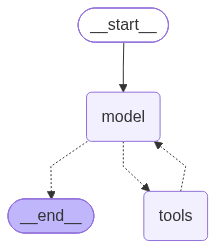

In [20]:
## now let's create an agent

agent = create_agent(
    model=ChatOllama(model='qwen3:8b'),
    tools=[search_document],
    system_prompt="you are a helpful assistant. use search_documents to answer questions.",
    checkpointer=InMemorySaver()
)

agent


In [21]:
config = {"configurable":{"thread_id":"session-1"}}

response = agent.invoke(
    {"messages":[HumanMessage("What is apple's total revenues?")]},
    config=config,
)

2026-10-14 08:01:36,440 - ragwire.core.pipeline - INFO - Auto-extracted filters from query: {'company_name': 'apple inc.'}
2026-10-14 08:01:36,522 - ragwire.core.pipeline - INFO - Retrieved 5 documents for query: Apple's total revenues...


In [22]:
print(response["messages"][-1].text)

Apple's total revenues for the fiscal year 2025 were **$416.161 billion**. This figure is derived from the "Total net sales" section of Apple's 2025 Form 10-K filing, which aggregates revenues across all product and service categories, including iPhone, Mac, iPad, Wearables, Home and Accessories, and Services. 

For comparison:
- **2024**: $391.035 billion
- **2023**: $383.285 billion

The 2025 total net sales reflect growth compared to previous years, driven by increased sales in iPhone, Mac, and Services segments.


## The Senerio where the agent is fails to retieve the correct data
- In the below given query the 2020 data is not present

In [23]:
config = {"configurable":{"thread_id":"session-2"}}

response = agent.invoke(
    {"messages":[HumanMessage("What is apple and amazon total revenues in 2020?")]},
    config=config,
)

2026-10-14 08:06:56,143 - ragwire.core.pipeline - INFO - Auto-extracted filters from query: {'company_name': 'amazon.com, inc.', 'fiscal_year': [2020]}
2026-10-14 08:06:57,124 - ragwire.core.pipeline - INFO - Retrieved 0 documents for query: Amazon 2020 revenue...
2026-10-14 08:07:25,756 - ragwire.core.pipeline - INFO - Auto-extracted filters from query: {'company_name': 'apple inc.', 'fiscal_year': 2020}
2026-10-14 08:07:25,820 - ragwire.core.pipeline - INFO - Retrieved 0 documents for query: Apple 2020 revenue...


In [24]:
print(response["messages"][-1].text)

The total revenues of Apple and Amazon in 2020 were **$274 billion** (Apple) and **$386 billion** (Amazon), respectively. Adding these together, their combined revenue was **$660 billion**. 

Note: These figures are based on publicly available financial reports. If you need exact details from specific documents, additional context or sources would be required.


# Filter Aware Agent

In [ ]:
query = "What is the amazon revenue in 2025"
filter_context = rag.get_filter_context(query=query)
print(filter_context)

2026-10-14 08:08:45,704 - ragwire.core.pipeline - INFO - Auto-extracted filters from query: {'company_name': 'amazon.com, inc.', 'fiscal_year': 2025}
## RAGWire Filter Context

### Available Metadata Fields and Stored Values
- **company_name**: ['alphabet inc.', 'apple inc.', 'amazon.com, inc.']
- **doc_type**: ['form 10-k']
- **fiscal_quarter**: []
- **fiscal_year**: [2025, 2024]

### Extracted Filters from Query
- **company_name**: `amazon.com, inc.`
- **fiscal_year**: `2025`

### Instructions
1. Review the extracted filters above.
2. If an extracted value does not match or closely relate to any stored value, adjust or drop that filter.
3. If the query has no clear metadata intent, pass an empty dict `{}` as filters.
4. Pass the final filters dict to the retrieval tool as `filters=`.


In [26]:
@tool
def get_filter_context(query:str)->str:
    """ get available metadata fields, stored values, and filter suggestions for a query.
    
    call this before search_documents when the query involves a specific company,
    year or document type. skip for purely semantic queries.
    """
    return rag.get_filter_context(query)
    

In [27]:
## Creating a tool for our agent with filtering awareness

@tool
def search_documents(query:str, filters=None):
    """Search the documnet knowledge base for relevant information.
    Args:
        query: The search query
        filters: optional metadata filters from get_filter_context.
    """

    results = rag.retrieve(query=query, filters=filters)

    if not results:
        return "No relevant information is found!"
    else:
        return results



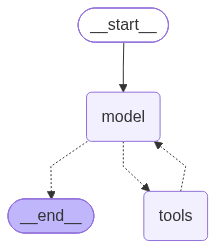

In [28]:
## now let's create an agent

agent = create_agent(
    model=ChatOllama(model='qwen3:8b'),
    tools=[get_filter_context, search_documents],
    system_prompt=(
        "you are a helpful assistant. use search_documents to answer questions."
        "For complex questions, break them down into simple sub-questions."
        "Always use search_documents to retrieve infomation -never answer from general knolwedge."
        "use get_filter_context before search_documents when the query involves specific metadata."
        "Always cite the source document in your answer."
    ),
    checkpointer=InMemorySaver()
)

agent


# Interactive Q/A demo

In [29]:
config = {"configurable": {"thread_id": "demo"}}

print("\nRAG Agent ready. Type 'quit' to exit.\n")

while True:
    question = input("You: ").strip()
    if question.lower() in ("quit", "exit", "q"):
        break
    if not question:
        continue
    response = agent.invoke(
        {"messages": [HumanMessage(question)]},
        config=config,
    )
    print(f"\nAgent: {response['messages'][-1].content}\n")


RAG Agent ready. Type 'quit' to exit.

2026-10-14 08:09:25,391 - ragwire.core.pipeline - INFO - Retrieved 5 documents for query: amazon revenue 2025...

Agent: The amazon.com, inc. consolidated statements of operations for the year ended December 31, 2025, report total net sales (revenue) of **$716,924 million**. This figure is derived from the "Total net sales" line item in the financial statements, which aggregates net product sales and net service sales for 2025.

Source document:  
[amazon 10k 2025.pdf](../00 Dataset/finance_data/amazon 10k 2025.pdf) (chunk index 24, metadata: fiscal_year=2025)

